In [2]:
%pylab inline
import os
import pandas as pd
import numpy as np
import astropy.io.fits as pyfits
import astropy.table as astTable
import catutil as utilities
import smatch
dbDir='./wrkDir/database/s19-COSMOS/wcut/'
outDir=   './wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/plot/others/'
if False:
    aname='/home/xiangchong/work/gw_ipmu/work/COSMOS/cosmos_leauthaud_2007/COSMOS_ACS_catalog/acs_clean_only.fits'
else:
    aname='/work/xiangchong.li/work/COSMOS/cosmos_leauthaud_2007/COSMOS_ACS_catalog/acs_clean_only.fits'

Populating the interactive namespace from numpy and matplotlib


# 3 catalogs

* HSC wdie_depth_best catalog (S16A sim)
* HSC wdie_depth_median catalog (S16A sim)
* HSC wdie_depth_worst catalog (S16A sim)

In [2]:
%pylab inline
import os
import pandas as pd
import numpy as np
import astropy.io.fits as pyfits
import astropy.table as astTable
import catutil as utilities
import smatch
dbDir='./wrkDir/database/s19-COSMOS/wcut/'
outDir=   './wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/plot/others/'
if False:
    aname='/home/xiangchong/work/gw_ipmu/work/COSMOS/cosmos_leauthaud_2007/COSMOS_ACS_catalog/acs_clean_only.fits'
else:
    aname='/work/xiangchong.li/work/COSMOS/cosmos_leauthaud_2007/COSMOS_ACS_catalog/acs_clean_only.fits'

In [25]:
# self match
cat0=astTable.Table.read(aname)
fmsk=(cat0['MU_CLASS']==1)
cat0=cat0[fmsk]
ra=cat0['ALPHAPEAK_J2000']
dec=cat0['DELTAPEAK_J2000']
bmatch   =   smatch.match(ra,dec,30./3600.,ra,dec,nside=4096,maxmatch=2)
inds=np.lexsort((bmatch['cosdist'],bmatch['i2']))
bmatchR=bmatch[inds][::2]
dist=np.sqrt((ra[bmatchR['i1']]-ra[bmatchR['i2']])**2.+(dec[bmatchR['i1']]-dec[bmatchR['i2']])**2.)

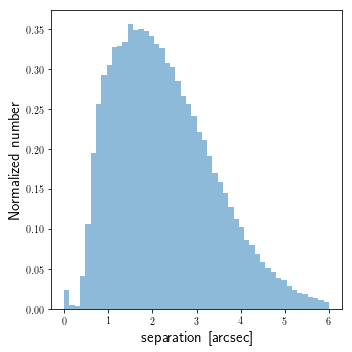

In [61]:
mask2=(cat0['MAG_AUTO']<24.5)&(cat0['FLUX_AUTO']/cat0['FLUXERR_AUTO']>10.)
plt.close()
fig=plt.figure(figsize=(5,5))
ax=fig.add_subplot(1,1,1)
ax.hist(dist[mask2]*3600.,bins=50,range=(0.,6.),density=True,alpha=0.5)
ax.set_xlabel('separation [arcsec]',fontsize=15)
ax.set_ylabel('Normalized number',fontsize=15)
plt.tight_layout()

# Three differences to DES sim:
### We do not have redshift-dependent shear, but DES sims have;
redshift-dependent shear matters when light from neighboring galaxies are not sucessfully detected (unrecognized blending) and fully removed (debelnding errors).

### We have better histogram matches between data and sims, especially for size hsitogram;
A mis-match in size histogram might be a reflection of failure in reproducing realistic undetected blendings (see HSC Y1 simulation paper);

### We run deblending then calibrate, DES does not deblend;
Light from neighbouring galaxies are fully reserved on the image of the galaxy to measrue; however, we do 
try removing the light from neighboring galaxies with deblender.

In [ ]:
6